# Bài 08 — Đổi cơ sở và phép xoay trục với NumPy

Tài liệu đi kèm gồm [lý thuyết](notes.md) và [ứng dụng PCA với dữ liệu cảm biến](ml-in-practice.md).

## Mục tiêu

- Giải tọa độ theo một cơ sở xiên, đổi sang cơ sở thứ hai và kiểm tra kết quả bằng cách dựng lại vector.
- Dự đoán hướng khi xoay vector hoặc xoay hệ trục, cho một điểm và cho cả batch.
- Biểu diễn phép biến đổi tuyến tính trong một cơ sở mới.
- Học cơ sở PCA trên train, dựng lại dữ liệu mới và tìm tín hiệu bị mất khi chỉ giữ một trục.

Tính thử trên giấy trước khi chạy các ví dụ. Cuối notebook có bảy bài tự làm và một bài tổng hợp, mỗi bài có ô kiểm tra và đáp án thu gọn.

## 0. Khởi tạo

Các phép tính dùng NumPy. Matplotlib vẽ hai hệ trục ở mục 4. Vector một chiều có shape `(d,)`, batch có shape `(N, d)` và mỗi cột của ma trận cơ sở là một hướng.

In [1]:
import numpy as np

rng = np.random.default_rng(42)
ATOL = 1e-12

## 1. Đi theo các cột để tới cùng một điểm

Một bước theo $b_1=(1,0)^T$ và hai bước theo $b_2=(1,1)^T$ có đưa ta tới $x=(3,2)^T$ không? Tính tay $B^Tx$ rồi đối chiếu với bộ hệ số của bạn. Vì sao hai kết quả khác nhau?

In [2]:
B = np.array([[1., 1.], [0., 1.]])
x = np.array([3., 2.])
c_B = np.linalg.solve(B, x)
gram = B.T @ B
print("Tọa độ theo B", c_B, "  Tích với các cột", B.T @ x)
np.testing.assert_allclose(c_B, [1., 2.])
np.testing.assert_allclose(B @ c_B, x)
np.testing.assert_allclose(c_B @ gram @ c_B, x @ x)

Tọa độ theo B [1. 2.]   Tích với các cột [3. 5.]


## 2. Đi từ cơ sở $B$ sang cơ sở $C$

Các cột của $C$ là $(1,1)^T$ và $(-1,1)^T$. Hãy viết tọa độ của từng $b_j$ theo $C$ trước khi chạy ô sau. Ghép hai kết quả thành cột cho ta $T_{C\leftarrow B}$. Dùng cùng ma trận đó để chuyển một vector khác bằng cách thay `c_B`.

In [3]:
C = np.array([[1., -1.], [1., 1.]])
to_C = np.linalg.solve(C, B)
to_B = np.linalg.solve(B, C)
c_C = to_C @ c_B
print("Ma trận chuyển B sang C\n", to_C, "\nTọa độ trong C", c_C)
np.testing.assert_allclose(C @ to_C, B)
np.testing.assert_allclose(c_C, np.linalg.solve(C, B @ c_B))
np.testing.assert_allclose(to_B @ to_C, np.eye(2), atol=ATOL)

Ma trận chuyển B sang C
 [[ 0.5  1. ]
 [-0.5  0. ]] 
Tọa độ trong C [ 2.5 -0.5]


## 3. Xoay vector và xoay hệ trục

Cùng góc $+90^\circ$, hãy ghi hai kết quả riêng cho $e_1=(1,0)^T$. Với phép xoay hệ trục, tự hỏi phải đi bao nhiêu bước theo mỗi **trục mới** để chạm điểm cũ. Sau đó kiểm tra rằng xoay $30^\circ$ rồi $60^\circ$ cho cùng kết quả với xoay $90^\circ$.

In [4]:
def rotation(theta):
    """Ma trận xoay chủ động 2D. Góc theta tính bằng radian."""
    c, s = np.cos(theta), np.sin(theta)
    return np.array([[c, -s], [s, c]])

R30, R60, R90 = map(rotation, np.deg2rad([30., 60., 90.]))
e1 = np.array([1., 0.])
active = R90 @ e1
passive = R90.T @ e1
print("Mũi tên sau khi xoay", active.round(3), "  Tọa độ theo trục mới", passive.round(3))
np.testing.assert_allclose(active, [0., 1.], atol=ATOL)
np.testing.assert_allclose(passive, [0., -1.], atol=ATOL)
np.testing.assert_allclose(R90 @ passive, e1, atol=ATOL)
np.testing.assert_allclose(R60 @ R30, R90, atol=ATOL)
np.testing.assert_allclose(R30.T, rotation(np.deg2rad(-30.)), atol=ATOL)
np.testing.assert_allclose(R30.T @ R30, np.eye(2), atol=ATOL)
np.testing.assert_allclose(np.linalg.det(R30), 1.)

Mũi tên sau khi xoay [0. 1.]   Tọa độ theo trục mới [ 0. -1.]


## 4. Vẽ hai phép xoay cạnh nhau

Hai hình dùng chung khung tọa độ chuẩn. Bên trái, quan sát đầu mũi tên đổi vị trí. Bên phải, theo nét đứt từ gốc dọc trục $b_1$ rồi song song với $b_2$ để tới mũi tên ban đầu. Thử đổi `angle_deg` từ $30^\circ$ thành $-30^\circ$. Dự đoán dấu của tọa độ thứ hai trước khi chạy lại.

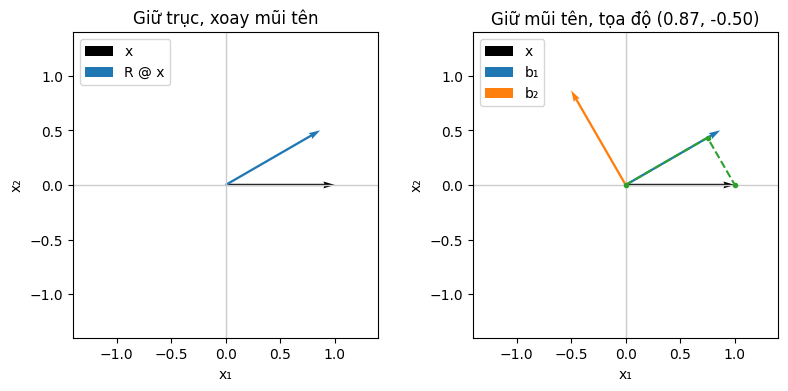

In [5]:
import matplotlib.pyplot as plt

angle_deg = 30
R = rotation(np.deg2rad(angle_deg))
coords = R.T @ e1
along_first = coords[0] * R[:, 0]
fig, axes = plt.subplots(1, 2, figsize=(8, 3.8), constrained_layout=True)
for ax in axes:
    ax.set(xlim=(-1.4, 1.4), ylim=(-1.4, 1.4), aspect="equal", xlabel="x₁", ylabel="x₂")
    ax.axhline(0, color="0.8", lw=1)
    ax.axvline(0, color="0.8", lw=1)
    ax.quiver(0, 0, *e1, angles="xy", scale_units="xy", scale=1, color="black", label="x")

axes[0].quiver(0, 0, *(R @ e1), angles="xy", scale_units="xy", scale=1,
               color="tab:blue", label="R @ x")
axes[0].set_title("Giữ trục, xoay mũi tên")
for direction, label, color in zip(R.T, ["b₁", "b₂"], ["tab:blue", "tab:orange"]):
    axes[1].quiver(0, 0, *direction, angles="xy", scale_units="xy", scale=1,
                   color=color, label=label)
path = np.stack([np.zeros(2), along_first, e1])  # gốc → c₁b₁ → c₁b₁ + c₂b₂
axes[1].plot(path[:, 0], path[:, 1], "o--", color="tab:green", lw=1.5, ms=3)
axes[1].set_title(f"Giữ mũi tên, tọa độ ({coords[0]:.2f}, {coords[1]:.2f})")
for ax in axes:
    ax.legend(loc="upper left")
plt.show()

## 5. Xoay một tập điểm theo hàng

Hàng đầu là điểm mốc có đáp án biết trước, các hàng còn lại là điểm ngẫu nhiên. Cả hai tích dưới đây đều cho mảng `(5, 2)` và bảo toàn độ dài từng hàng. Phép thử nào giúp bạn biết tích nào xoay **điểm**?

In [6]:
X = np.vstack([e1, rng.normal(size=(4, 2))])
points_rotated = X @ R30.T
coords_rotated_axes = X @ R30
print("Điểm mốc sau khi xoay", points_rotated[0])
print("Điểm mốc theo trục mới", coords_rotated_axes[0])
np.testing.assert_allclose(points_rotated[0], [np.sqrt(3)/2, .5])
np.testing.assert_allclose(coords_rotated_axes[0], [np.sqrt(3)/2, -.5])
np.testing.assert_allclose(np.linalg.norm(points_rotated, axis=1), np.linalg.norm(X, axis=1))
np.testing.assert_allclose(coords_rotated_axes @ R30.T, X, atol=ATOL)

batch_B = np.linalg.solve(B, X.T).T      # (5, 2), cùng 5 điểm theo cơ sở xiên
np.testing.assert_allclose(batch_B @ B.T, X, atol=ATOL)

Điểm mốc sau khi xoay [0.8660254 0.5      ]
Điểm mốc theo trục mới [ 0.8660254 -0.5      ]


## 6. Cùng một phép kéo dãn trong hai cơ sở

Phép $A$ nhân đôi tọa độ ngang. Tính $Ax$ trong hệ chuẩn. Theo đường thứ hai, áp dụng $A_B$ cho $[x]_B$ rồi mới trở về hệ chuẩn. Hai đường phải kết thúc tại cùng một điểm.

In [7]:
A = np.diag([2., 1.])
A_B = np.linalg.solve(B, A @ B)
print("Ma trận của ánh xạ theo B\n", A_B)
np.testing.assert_allclose(A_B, [[2., 1.], [0., 1.]])
np.testing.assert_allclose(A_B @ c_B, [4., 2.])
np.testing.assert_allclose(B @ (A_B @ c_B), A @ x)

Ma trận của ánh xạ theo B
 [[2. 1.]
 [0. 1.]]


## 7. Học trục PCA từ bốn lần đo

Hai nhiệt kế đo cùng một phòng. Dựa vào các cặp dưới đây, hãy vẽ hướng biến thiên lớn nhất. Dùng SVD của dữ liệu đã trừ trung bình để tìm cơ sở. So sánh sai số tái tạo khi giữ đủ hai trục và khi chỉ giữ trục đầu. Dấu do SVD chọn cho từng trục có thể khác dấu bạn vẽ.

In [8]:
thermometers = np.array([[16., 16.], [20., 20.], [17., 19.], [19., 17.]])
mu = thermometers.mean(axis=0)
centered = thermometers - mu
_, s, Vt = np.linalg.svd(centered, full_matrices=False)
Q = Vt.T
scores = centered @ Q
restored_one = scores[:, :1] @ Q[:, :1].T + mu
print("Tỷ lệ phương sai từng trục", s**2 / np.sum(s**2))
print("Sai số bình phương trung bình từng mẫu", np.mean((thermometers - restored_one)**2, axis=1))
np.testing.assert_allclose(s**2 / np.sum(s**2), [.8, .2])
np.testing.assert_allclose(scores @ Q.T + mu, thermometers)
np.testing.assert_allclose(restored_one, [[16., 16.], [20., 20.], [18., 18.], [18., 18.]])
np.testing.assert_allclose((thermometers - restored_one) @ Q[:, :1], 0., atol=ATOL)

Tỷ lệ phương sai từng trục [0.8 0.2]
Sai số bình phương trung bình từng mẫu [0. 0. 1. 1.]


## Bài tập

Sau mục 0, chạy ô `ready` dưới đây. Mỗi bài cung cấp dữ liệu riêng. Thay các dòng `# TODO` bằng mã của bạn rồi chạy ô kiểm tra ngay sau đó. Nếu còn thiếu biến, ô kiểm tra sẽ in tên biến cần điền. Mở đáp án thu gọn sau khi đã tự thử.

In [9]:
def ready(*names):
    missing = [name for name in names if name not in globals()]
    if missing:
        print("Cần điền TODO cho " + ", ".join(missing))
    return not missing

### Bài 1 — Hai trục vuông góc có độ dài khác 1

Cho $x=(3,1)^T$ và hai trục $b_1=(1,1)^T$, $b_2=(1,-1)^T$. Tính tọa độ bằng tay rồi bằng `solve`. Tính riêng $B^Tx$, tìm hệ số tỉ lệ giữa hai kết quả và dựng lại $x$ từ tọa độ.

In [10]:
basis1 = np.array([[1., 1.], [1., -1.]])
x1 = np.array([3., 1.])
# TODO: coords1 = ...
# TODO: dots1 = ...
# TODO: rebuilt1 = ...

In [11]:
if ready("coords1", "dots1", "rebuilt1"):
    assert coords1.shape == dots1.shape == rebuilt1.shape == (2,)
    np.testing.assert_allclose(coords1, [2., 1.])
    np.testing.assert_allclose(dots1, 2 * coords1)
    np.testing.assert_allclose(rebuilt1, x1)
    print("Bài 1 đạt.")

Cần điền TODO cho coords1, dots1, rebuilt1


<details>
<summary>Đáp án Bài 1</summary>

```python
coords1 = np.linalg.solve(basis1, x1)
dots1 = basis1.T @ x1
rebuilt1 = basis1 @ coords1
```

Mỗi cột có bình phương độ dài bằng 2. Vì $B^TB=2I$, tích $B^Tx$ gấp đôi bộ hệ số.

</details>

### Bài 2 — Chuyển cả batch giữa hai cơ sở xiên

Các hàng của `source2` đang ở hệ $B$. Tìm ma trận chuyển từ $B$ sang $C$, tọa độ theo $C$ của từng hàng và ma trận chuyển ngược lại. Dựng lại cùng ba điểm trong hệ chuẩn để kiểm tra.

In [12]:
B2 = np.array([[2., 1.], [0., 1.]])
C2 = np.array([[1., 0.], [1., 1.]])
source2 = np.array([[1., 2.], [-1., 1.], [0., 3.]])
# TODO: to_C2 = ...
# TODO: target2 = ...
# TODO: to_B2 = ...

In [13]:
if ready("to_C2", "target2", "to_B2"):
    assert to_C2.shape == to_B2.shape == (2, 2) and target2.shape == (3, 2)
    np.testing.assert_allclose(C2 @ to_C2, B2, atol=ATOL)
    np.testing.assert_allclose(target2[0], [4., -2.])
    np.testing.assert_allclose(target2 @ C2.T, source2 @ B2.T)
    np.testing.assert_allclose(to_B2 @ to_C2, np.eye(2), atol=ATOL)
    np.testing.assert_allclose(target2 @ to_B2.T, source2, atol=ATOL)
    print("Bài 2 đạt.")

Cần điền TODO cho to_C2, target2, to_B2


<details>
<summary>Đáp án Bài 2</summary>

```python
to_C2 = np.linalg.solve(C2, B2)
target2 = source2 @ to_C2.T
to_B2 = np.linalg.solve(B2, C2)
```

Điểm đầu có tọa độ chuẩn $(4,2)^T$. Trong cơ sở $C$, bốn bước theo $(1,1)^T$ rồi lùi hai bước theo $(0,1)^T$ cho đúng điểm đó.

</details>

### Bài 3 — Tự viết phép xoay và ghép góc

Viết hàm `turn3(theta)` với góc tính bằng radian. Xoay chủ động $(2,0)^T$ lần lượt $+30^\circ$ và $+60^\circ$. Đọc riêng tọa độ của **điểm ban đầu** khi trục xoay tổng cộng $+90^\circ$.

In [14]:
x3 = np.array([2., 0.])
a3, b3 = np.deg2rad([30., 60.])
# TODO: def turn3(theta):
#           ...
# TODO: active3 = ...
# TODO: passive3 = ...

In [15]:
if ready("turn3", "active3", "passive3"):
    np.testing.assert_allclose(turn3(0.), np.eye(2), atol=ATOL)
    np.testing.assert_allclose(turn3(-a3) @ x3, [np.sqrt(3), -1.], atol=ATOL)
    np.testing.assert_allclose(turn3(b3) @ turn3(a3), turn3(a3 + b3), atol=ATOL)
    np.testing.assert_allclose(active3, [0., 2.], atol=ATOL)
    np.testing.assert_allclose(passive3, [0., -2.], atol=ATOL)
    np.testing.assert_allclose(turn3(a3 + b3) @ passive3, x3, atol=ATOL)
    print("Bài 3 đạt.")

Cần điền TODO cho turn3, active3, passive3


<details>
<summary>Đáp án Bài 3</summary>

```python
def turn3(theta):
    c, s = np.cos(theta), np.sin(theta)
    return np.array([[c, -s], [s, c]])

active3 = turn3(b3) @ (turn3(a3) @ x3)
passive3 = turn3(a3 + b3).T @ x3
```

Khi xoay trục một phần tư vòng, trục thứ hai mới hướng sang trái. Để đi tới điểm nằm bên phải gốc, tọa độ thứ hai phải âm.

</details>

### Bài 4 — Tìm lỗi xoay điểm theo batch

Một đoạn mã định xoay chủ động bốn điểm nhưng viết `X4 @ R4`. Hãy tính kết quả đúng, tìm **chỉ số hàng** mà hai cách cho kết quả khác nhau và hoàn tác phép xoay đúng. Vì sao so độ dài từng hàng sẽ bỏ sót lỗi?

In [16]:
X4 = np.array([[1., 0.], [0., 0.], [0., 2.], [-1., 3.]])
R4 = np.array([[.6, -.8], [.8, .6]])
suspect4 = X4 @ R4
# TODO: rotated4 = ...
# TODO: changed4 = ...
# TODO: restored4 = ...

In [17]:
if ready("rotated4", "changed4", "restored4"):
    assert rotated4.shape == restored4.shape == X4.shape
    np.testing.assert_allclose(rotated4, np.stack([R4 @ row for row in X4]), atol=ATOL)
    np.testing.assert_array_equal(changed4, [0, 2, 3])
    np.testing.assert_allclose(restored4, X4, atol=ATOL)
    np.testing.assert_allclose(np.linalg.norm(rotated4, axis=1), np.linalg.norm(suspect4, axis=1))
    print("Bài 4 đạt.")

Cần điền TODO cho rotated4, changed4, restored4


<details>
<summary>Đáp án Bài 4</summary>

```python
rotated4 = X4 @ R4.T
changed4 = np.flatnonzero(np.linalg.norm(rotated4 - suspect4, axis=1) > ATOL)
restored4 = rotated4 @ R4
```

Gốc tọa độ ở hàng 1 đứng yên dưới cả hai phép xoay. Các hàng còn lại đi theo hai chiều ngược nhau, giữ nguyên norm.

</details>

### Bài 5 — Tọa độ nhạy đến đâu khi hai trục gần song song?

Hai cột của `B5` chỉ chênh nhau một lượng rất nhỏ ở chiều đứng. Tính tọa độ của điểm ban đầu và điểm sau khi tăng chiều đứng thêm $\varepsilon$. Tính hệ số khuếch đại $\|\Delta c\|_2/\|\Delta x\|_2$. Hãy thử dự đoán hệ số này thay đổi thế nào nếu giảm cả `eps5` và độ dịch tương ứng mười lần.

In [18]:
eps5 = 1e-4
B5 = np.array([[1., 1.], [0., eps5]])
x5 = np.array([2., 0.])
shift5 = np.array([0., eps5])
# TODO: before5 = ...
# TODO: after5 = ...
# TODO: gain5 = ...

In [19]:
if ready("before5", "after5", "gain5"):
    np.testing.assert_allclose(before5, [2., 0.], atol=ATOL)
    np.testing.assert_allclose(after5, [1., 1.], atol=ATOL)
    np.testing.assert_allclose(B5 @ (after5 - before5), shift5, atol=ATOL)
    np.testing.assert_allclose(gain5, np.sqrt(2) / eps5)
    print("Bài 5 đạt.")

Cần điền TODO cho before5, after5, gain5


<details>
<summary>Đáp án Bài 5</summary>

```python
before5 = np.linalg.solve(B5, x5)
after5 = np.linalg.solve(B5, x5 + shift5)
gain5 = np.linalg.norm(after5 - before5) / np.linalg.norm(shift5)
```

Một bước chuyển từ trục thứ nhất sang trục thứ hai đủ tạo ra độ dịch đứng $\varepsilon$. Độ thay đổi tọa độ vẫn là $\sqrt{2}$ khi giảm $\varepsilon$, nên hệ số khuếch đại tăng mười lần.

</details>

### Bài 6 — Viết ma trận của một ánh xạ trong hệ mới

Trong hệ chuẩn, $A$ xoay điểm $90^\circ$ ngược chiều kim đồng hồ. Tính ma trận $A_B$ khi cả đầu vào lẫn đầu ra viết theo cơ sở xiên $B$. Áp dụng cho `input6` (đã ở hệ $B$) rồi dựng đầu ra trong hệ chuẩn.

In [20]:
A6 = np.array([[0., -1.], [1., 0.]])
B6 = np.array([[1., 1.], [0., 1.]])
input6 = np.array([2., -1.])
# TODO: matrix6 = ...
# TODO: output6 = ...
# TODO: standard6 = ...

In [21]:
if ready("matrix6", "output6", "standard6"):
    assert matrix6.shape == (2, 2) and output6.shape == standard6.shape == (2,)
    np.testing.assert_allclose(B6 @ matrix6, A6 @ B6)
    np.testing.assert_allclose(output6, [0., 1.], atol=ATOL)
    np.testing.assert_allclose(standard6, A6 @ (B6 @ input6))
    print("Bài 6 đạt.")

Cần điền TODO cho matrix6, output6, standard6


<details>
<summary>Đáp án Bài 6</summary>

```python
matrix6 = np.linalg.solve(B6, A6 @ B6)
output6 = matrix6 @ input6
standard6 = B6 @ output6
```

Đầu vào trong hệ chuẩn là $(1,-1)^T$. Xoay một phần tư vòng được $(1,1)^T$, chính là cột thứ hai của $B$. Vì vậy tọa độ đầu ra trong $B$ là $(0,1)^T$.

</details>

### Bài 7 — Đo sai số tái tạo trên từng mẫu mới

Cho hệ trực chuẩn của hai nhiệt kế đã học từ tập train, với cột đầu đo biến thiên chung. Mã hóa ba mẫu mới bằng đủ hai tọa độ. Dựng lại với **một** tọa độ rồi tính MSE trên hai cảm biến cho mỗi mẫu. Liên hệ MSE với bình phương tọa độ thứ hai.

In [22]:
mu7 = np.array([18., 18.])
Q7 = np.array([[1., -1.], [1., 1.]]) / np.sqrt(2)
new7 = np.array([[19., 19.], [17., 21.], [20., 18.]])
# TODO: scores7 = ...
# TODO: restored7 = ...
# TODO: mse7 = ...

In [23]:
if ready("scores7", "restored7", "mse7"):
    assert scores7.shape == restored7.shape == (3, 2) and mse7.shape == (3,)
    np.testing.assert_allclose(scores7, np.array([[1., 0.], [1., 2.], [1., -1.]]) * np.sqrt(2), atol=ATOL)
    np.testing.assert_allclose(restored7, [[19., 19.]] * 3)
    np.testing.assert_allclose(mse7, [0., 4., 1.], atol=ATOL)
    np.testing.assert_allclose(mse7, scores7[:, 1]**2 / 2, atol=ATOL)
    print("Bài 7 đạt.")

Cần điền TODO cho scores7, restored7, mse7


<details>
<summary>Đáp án Bài 7</summary>

```python
scores7 = (new7 - mu7) @ Q7
restored7 = scores7[:, :1] @ Q7[:, :1].T + mu7
mse7 = np.mean((new7 - restored7)**2, axis=1)
```

Ba mẫu có cùng tọa độ trên trục chung. Bình phương tọa độ bị bỏ bằng tổng bình phương sai số của hai cảm biến. Chia cho 2 để được MSE.

</details>

## Bài tổng hợp — Nén dữ liệu ba cảm biến và tìm lần đo bất đồng

Ba nhiệt kế trong một phòng thường biến thiên cùng nhau. Sáu lần đo train dùng để học cơ sở PCA. Bốn lần đo mới dùng để kiểm tra liệu chỉ lưu một tọa độ có che khuất chênh lệch giữa các nhiệt kế hay không.

1. Tính trung bình từng cột của `train`. Dùng SVD trên train đã trừ trung bình để lấy một ma trận có các trục chính làm cột, theo thứ tự phương sai giảm dần. Tính tỷ lệ phương sai train của mỗi trục.
2. Dùng cùng trung bình và cơ sở để mã hóa `new`. Dựng lại với đủ ba trục rồi chỉ với trục đầu. Trước khi chạy, hãy tìm hai hàng có thể có cùng tọa độ trên trục chung.
3. Tính phần dư (số đo trừ giá trị dựng lại) và MSE trên ba nhiệt kế cho từng hàng khi nén. Tìm chỉ số các hàng có MSE vượt $1\,^\circ\mathrm{C}^2$ và ở mỗi hàng đó, chỉ số cảm biến có độ lệch tuyệt đối lớn nhất. Chỉ số bắt đầu từ 0.
4. Giải thích vì sao các mã một chiều của ba hàng cuối trùng nhau, còn cảm biến lệch nhất lại khác nhau. Ngưỡng ở đây được cho sẵn để luyện đọc kết quả.

In [24]:
train = np.array([[15., 15., 15.], [21., 21., 21.],
                  [19., 17., 18.], [17., 19., 18.],
                  [18.5, 18.5, 17.], [17.5, 17.5, 19.]])
new = np.array([[22., 22., 22.], [18., 21., 21.],
                [21., 18., 21.], [21., 21., 18.]])
# TODO: train_mean = ...
# TODO: pca_axes = ...
# TODO: variance_ratio = ...
# TODO: new_scores = ...
# TODO: full_restore = ...
# TODO: one_restore = ...
# TODO: residual = ...
# TODO: per_row_mse = ...
# TODO: flagged_rows = ...
# TODO: sensor_ids = ...

In [25]:
if ready("train_mean", "pca_axes", "variance_ratio", "new_scores", "full_restore", "one_restore", "residual", "per_row_mse", "flagged_rows", "sensor_ids"):
    assert train_mean.shape == variance_ratio.shape == (3,) and pca_axes.shape == (3, 3)
    assert new_scores.shape == full_restore.shape == one_restore.shape == residual.shape == new.shape
    assert per_row_mse.shape == (len(new),)
    np.testing.assert_allclose(train_mean, [18., 18., 18.])
    np.testing.assert_allclose(pca_axes.T @ pca_axes, np.eye(3), atol=ATOL)
    train_scores = (train - train_mean) @ pca_axes
    np.testing.assert_allclose(train_scores.T @ train_scores, np.diag([54., 4., 3.]), atol=ATOL)
    np.testing.assert_allclose(variance_ratio, np.array([54., 4., 3.]) / 61)
    np.testing.assert_allclose(new_scores, (new - train_mean) @ pca_axes, atol=ATOL)
    np.testing.assert_allclose(full_restore, new, atol=ATOL)
    np.testing.assert_allclose(one_restore, [[22.] * 3] + [[20.] * 3] * 3)
    np.testing.assert_allclose(residual, new - one_restore, atol=ATOL)
    np.testing.assert_allclose(residual @ pca_axes[:, :1], 0., atol=ATOL)
    np.testing.assert_allclose(per_row_mse, [0., 2., 2., 2.], atol=ATOL)
    np.testing.assert_array_equal(flagged_rows, [1, 2, 3])
    np.testing.assert_array_equal(sensor_ids, [0, 1, 2])
    print("Bài tổng hợp đạt.")

Cần điền TODO cho train_mean, pca_axes, variance_ratio, new_scores, full_restore, one_restore, residual, per_row_mse, flagged_rows, sensor_ids


<details>
<summary>Đáp án Bài tổng hợp</summary>

```python
train_mean = train.mean(axis=0)
_, singular_values, Vt_train = np.linalg.svd(train - train_mean, full_matrices=False)
pca_axes = Vt_train.T
variance_ratio = singular_values**2 / np.sum(singular_values**2)
new_scores = (new - train_mean) @ pca_axes
full_restore = new_scores @ pca_axes.T + train_mean
one_restore = new_scores[:, :1] @ pca_axes[:, :1].T + train_mean
residual = new - one_restore
per_row_mse = np.mean(residual**2, axis=1)
flagged_rows = np.flatnonzero(per_row_mse > 1.)
sensor_ids = np.argmax(np.abs(residual[flagged_rows]), axis=1)
```

Trục đầu dọc theo $(1,1,1)^T/\sqrt{3}$ và giữ $54/61$ phương sai train. Ba hàng cuối đều có nhiệt độ trung bình 20 °C nên được tái tạo thành $(20,20,20)$. Mỗi hàng có một phần dư $-2$ °C và hai phần dư $+1$ °C. Cả ba có MSE bằng 2 °C². Vị trí của $-2$ cho biết cảm biến nào lệch nhiều nhất so với mức chung.

</details>

## Tự kiểm tra nhanh

1. Để xác nhận chiều của $T_{C\leftarrow B}$, bạn nhân ma trận nào vào bên trái $T$ và mong đợi thu được gì?
2. Khi thay $\theta$ bằng $-\theta$ trong hình ở mục 4, tọa độ nào của $e_1$ theo hệ mới đổi dấu?
3. Với một cơ sở xiên, làm sao tính đúng độ dài hình học chỉ từ bộ tọa độ và các cột của cơ sở?
4. Nếu một lần chạy SVD đổi dấu trục đầu, mã một chiều, giá trị dựng lại và MSE thay đổi thế nào?
5. Trong bài tổng hợp, nếu cả ba nhiệt kế cùng tăng 5 °C, một cảnh báo chỉ dựa vào phần dư có phát hiện được sự kiện đó không?

## Tổng kết

- Giải $Bc=x$ để đọc tọa độ theo $B$. Giải $CT=B$ một lần để có thể chuyển nhiều vector từ $B$ sang $C$.
- Với dữ liệu theo hàng, `X @ R.T` xoay các điểm còn `X @ R` đọc chúng theo các trục đã xoay. Một điểm có đáp án biết trước giúp kiểm tra chiều.
- Với PCA, trung bình train xác định gốc và các cột của $Q$ xác định hướng. Giữ đủ trục cho phép dựng lại từng mẫu. Khi chỉ giữ trục chung của các nhiệt kế, phần dư đo mức độ bất đồng đã bị bỏ.

Trước Bài 09, hãy tìm một hướng mà phép kéo dãn ở mục 6 chỉ làm thay đổi độ dài. Nếu chọn hướng đó làm cột của cơ sở, cột tương ứng trong ma trận của ánh xạ sẽ có dạng gì?